# Music Sales from 1973 to 2013: an EDA

### First step: looking at the data

In [64]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme()

In [65]:
music_raw = pd.read_csv('musicdata/musicdata.csv')
music = music_raw.copy()
music.info()

<class 'pandas.DataFrame'>
RangeIndex: 3008 entries, 0 to 3007
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   format             3008 non-null   str    
 1   metric             3008 non-null   str    
 2   year               3008 non-null   int64  
 3   number_of_records  3008 non-null   int64  
 4   value_actual       1351 non-null   float64
dtypes: float64(1), int64(2), str(2)
memory usage: 117.6 KB


In [66]:
music.sample(10)

,format,metric,year,number_of_records,value_actual
2271,Download Music Video,Value (Adjusted),1988,1,NaN
197,LP/EP,Units,1982,1,243.900000
1912,Vinyl Single,Value,2005,1,13.200000
421,Music Video (Physical),Units,2018,1,1.395058
853,CD,Value,1980,1,NaN
553,Download Single,Units,2009,1,1124.400000
2137,Cassette Single,Value (Adjusted),1995,1,396.402553
2504,Music Video (Physical),Value (Adjusted),1986,1,NaN
2221,Download Album,Value (Adjusted),1985,1,NaN
2508,Music Video (Physical),Value (Adjusted),1990,1,337.029083


In [67]:
music['format'].unique()

<StringArray>
[                                'CD',                          'CD Single',
                           'Cassette',                    'Cassette Single',
                              'LP/EP',                       'Vinyl Single',
                          '8 - Track',                        'Other Tapes',
             'Music Video (Physical)',                          'DVD Audio',
                               'SACD',                    'Download Single',
                     'Download Album',                              'Kiosk',
               'Download Music Video',              'Ringtones & Ringbacks',
                 'Paid Subscriptions',     'Limited Tier Paid Subscription',
 'On-Demand Streaming (Ad-Supported)',       'Other Ad-Supported Streaming',
                      'Other Digital',                  'Paid Subscription',
        'SoundExchange Distributions',                    'Synchronization']
Length: 24, dtype: str

In [68]:
music['number_of_records'].unique()

array([1])

### Second step: cleaning the data

We don't need the number_of_records column as it is 1 everywhere. We shall drop it.

In [69]:
music.drop(columns='number_of_records',inplace=True)
music.info()

<class 'pandas.DataFrame'>
RangeIndex: 3008 entries, 0 to 3007
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   format        3008 non-null   str    
 1   metric        3008 non-null   str    
 2   year          3008 non-null   int64  
 3   value_actual  1351 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 94.1 KB


Now we check for NaNs.

In [70]:
music.info()

<class 'pandas.DataFrame'>
RangeIndex: 3008 entries, 0 to 3007
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   format        3008 non-null   str    
 1   metric        3008 non-null   str    
 2   year          3008 non-null   int64  
 3   value_actual  1351 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 94.1 KB


In [71]:
music[music['value_actual'].isna()].head(20)

,format,metric,year,value_actual
0,CD,Units,1973,NaN
1,CD,Units,1974,NaN
2,CD,Units,1975,NaN
3,CD,Units,1976,NaN
4,CD,Units,1977,NaN
5,CD,Units,1978,NaN
6,CD,Units,1979,NaN
7,CD,Units,1980,NaN
8,CD,Units,1981,NaN
9,CD,Units,1982,NaN


In [72]:
music[music['year']==1973]

,format,metric,year,value_actual
0,CD,Units,1973,NaN
47,CD Single,Units,1973,NaN
94,Cassette,Units,1973,15.000000
141,Cassette Single,Units,1973,NaN
188,LP/EP,Units,1973,280.000000
...,...,...,...,...
2773,Ringtones & Ringbacks,Value (Adjusted),1973,NaN
2820,SACD,Value (Adjusted),1973,NaN
2867,SoundExchange Distributions,Value (Adjusted),1973,NaN
2914,Synchronization,Value (Adjusted),1973,NaN


The only NaN values are in value_actual, that is the column containing the actual value of the metric. Therefore NaN values here have no use in our analysis and cannot be replaced with a relevant estimate since they represent missing data. We shall drop them.

In [73]:
music = music[~music['value_actual'].isna()]
music.info()

<class 'pandas.DataFrame'>
Index: 1351 entries, 10 to 3007
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   format        1351 non-null   str    
 1   metric        1351 non-null   str    
 2   year          1351 non-null   int64  
 3   value_actual  1351 non-null   float64
dtypes: float64(1), int64(1), str(2)
memory usage: 52.8 KB


In [74]:
music[(music['year']==1973) & (music['format']=='Cassette')]

,format,metric,year,value_actual
94,Cassette,Units,1973,15.000000
940,Cassette,Value,1973,76.000000
2068,Cassette,Value (Adjusted),1973,437.611081


In [75]:
music[(music['year']==1973) & (music['format']=='LP/EP')]

,format,metric,year,value_actual
188,LP/EP,Units,1973,280.000000
1316,LP/EP,Value,1973,1246.000000
2397,LP/EP,Value (Adjusted),1973,7174.518514


For each year, every format type has 3 different metrics: units, value and value (adjusted). Since we want to compare economic data coming from different periods of time, we can either deal with absolute units (i.e. volumes of sales) or the value adjusted for inflation. The latter is the best, for looking at units alone would not take into account any cost variation that is unrelated to inflation.

### Some plots

We first restrict to entries with Value (adjusted) as metric, and then we sum all those corresponding to same year but different format to determine the total value.

In [76]:
music_adj = music[music['metric']=='Value (Adjusted)']
music_adj.drop(columns='metric',inplace=True)
music_sales = music_adj.groupby(by='year',as_index=False)['value_actual'].sum()
music_sales.head()

,year,value_actual
0,1973,11611.664554
1,1974,11407.073081
2,1975,11350.125362
3,1976,12298.045250
4,1977,14769.043327


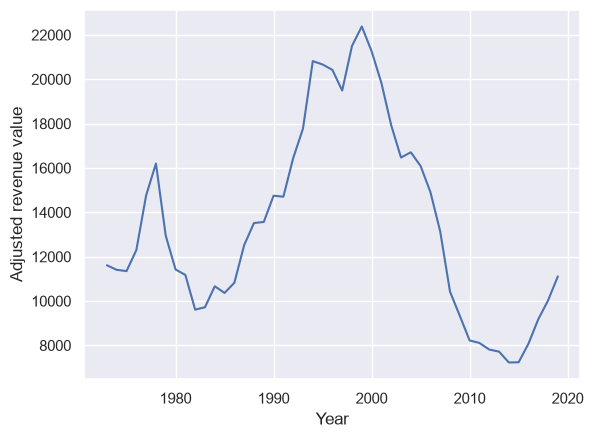

In [77]:
sns.lineplot(data=music_sales,x='year',y='value_actual');
plt.ylabel('Adjusted revenue value');
plt.xlabel('Year');

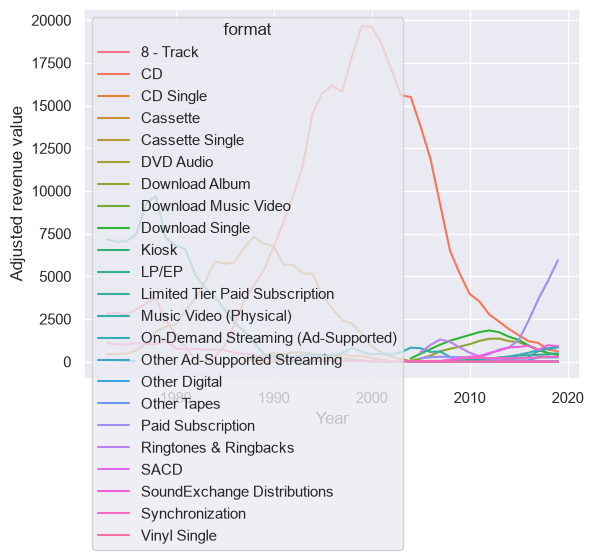

In [78]:
sns.lineplot(data=music_adj,x='year',y='value_actual',hue='format');
plt.ylabel('Adjusted revenue value');
plt.xlabel('Year');

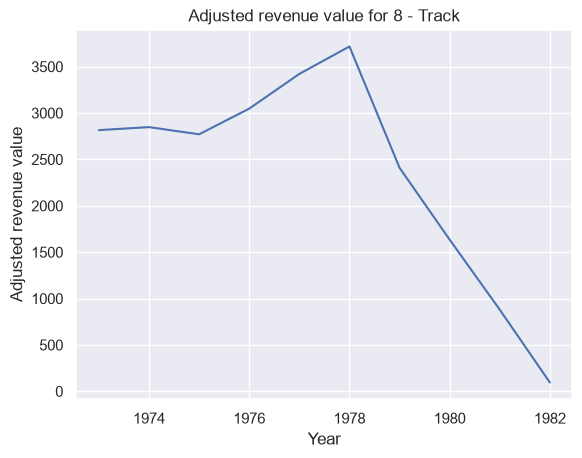

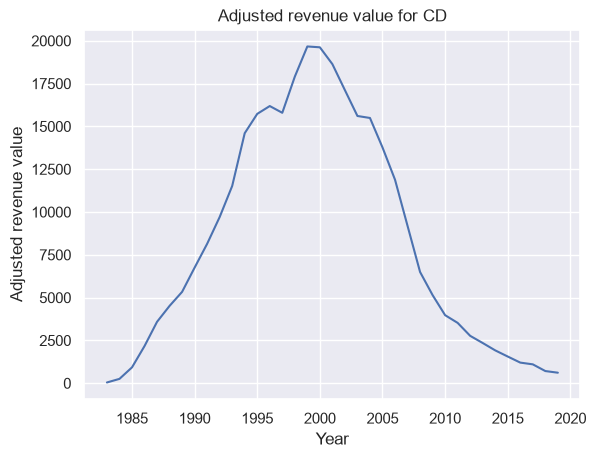

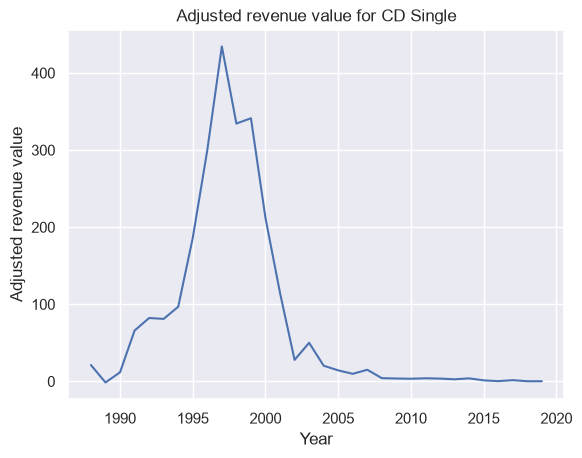

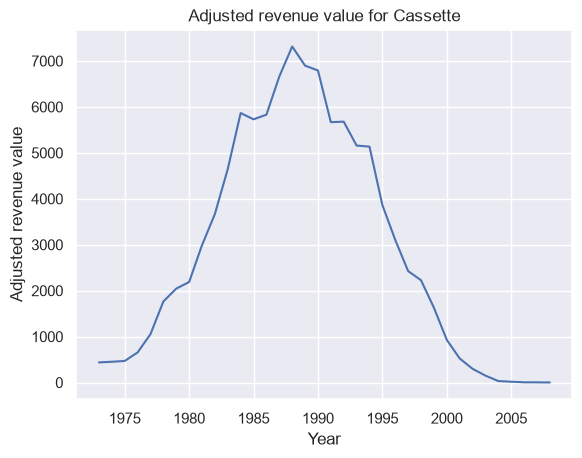

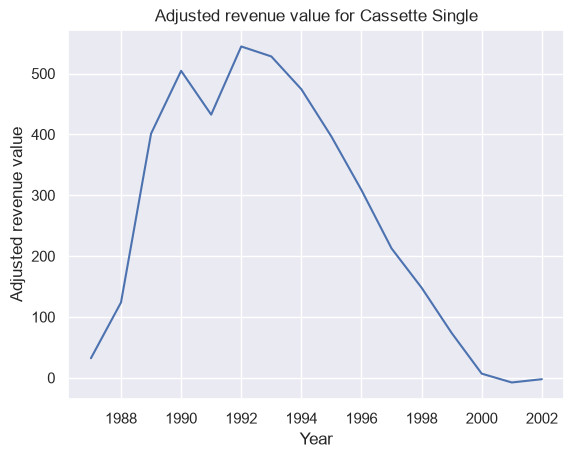

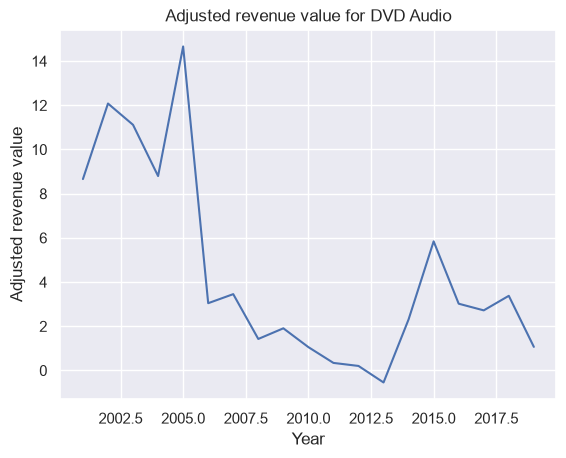

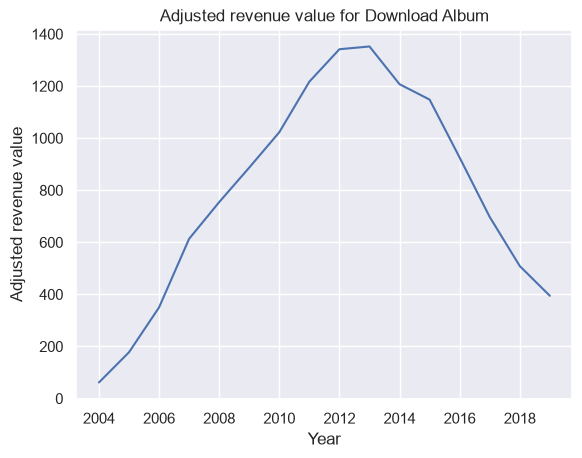

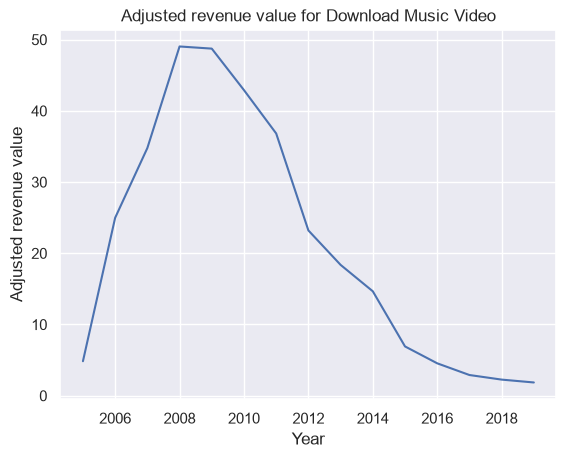

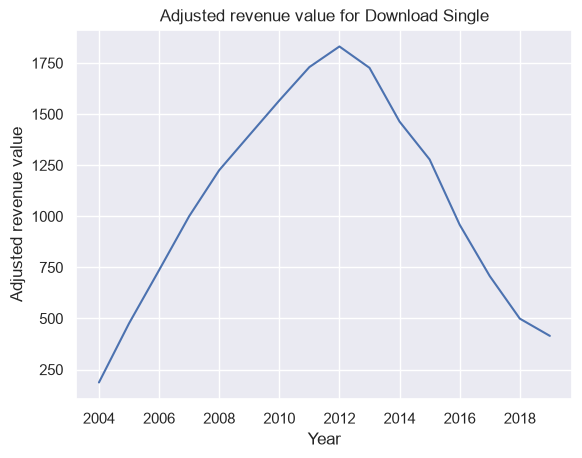

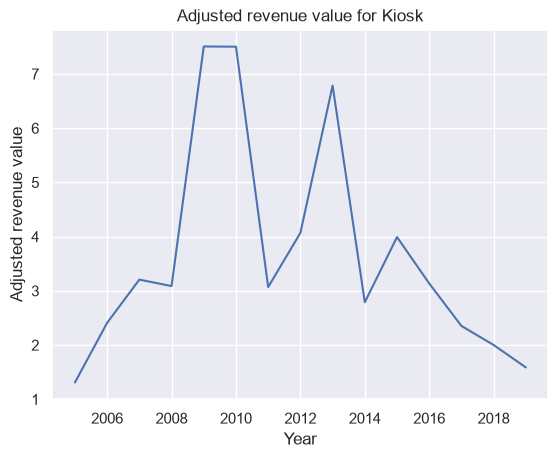

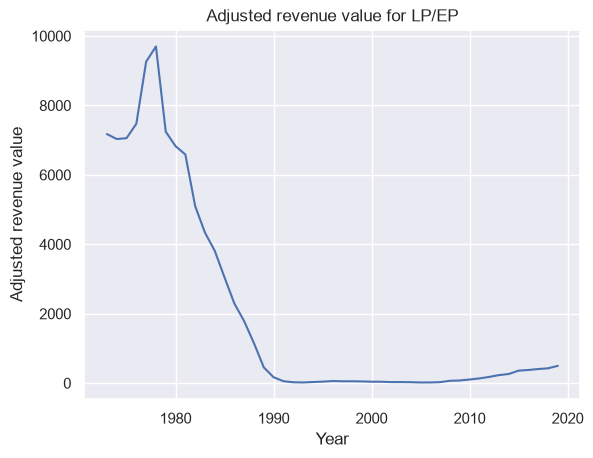

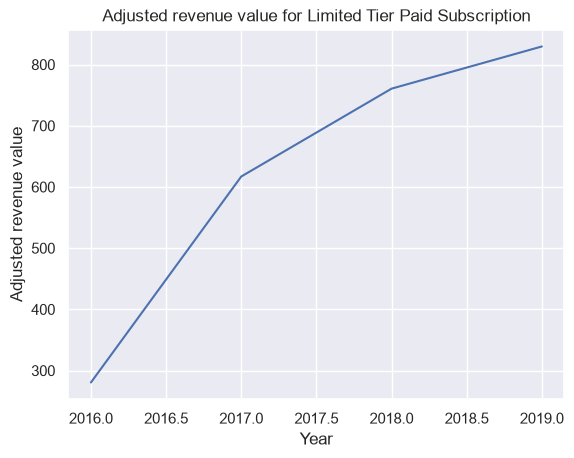

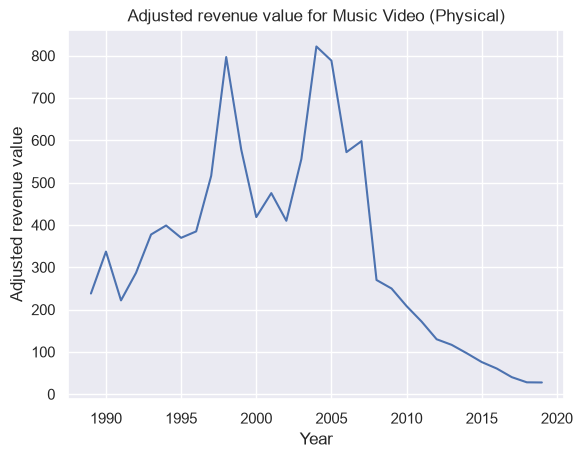

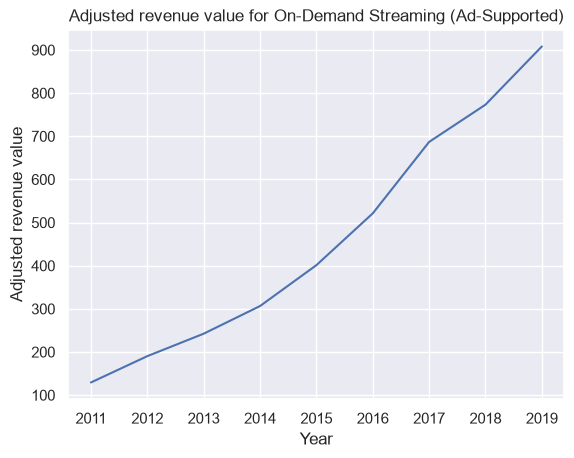

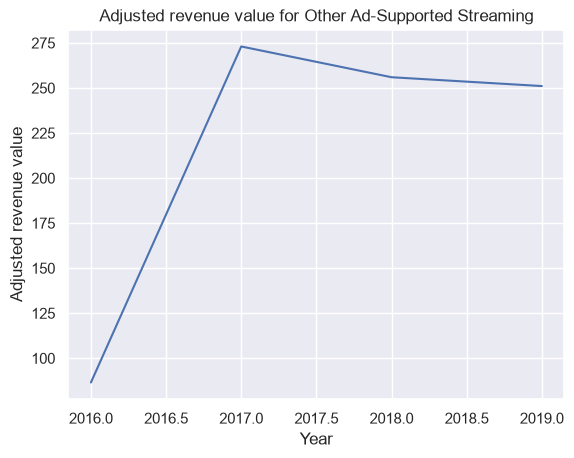

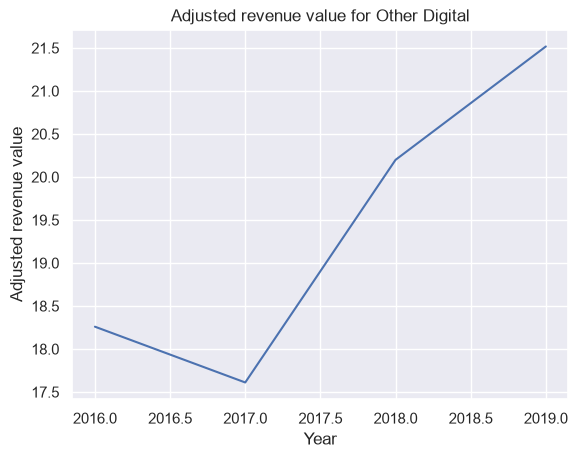

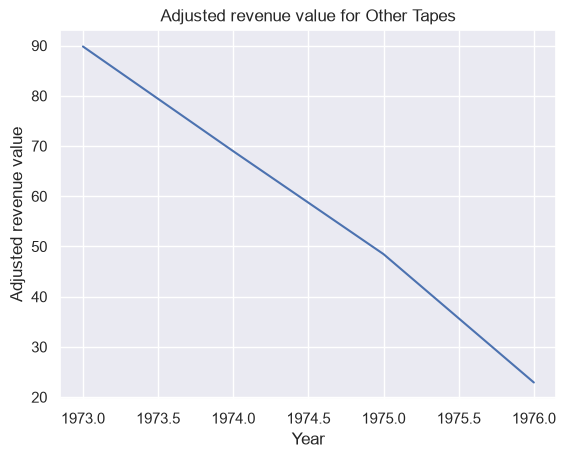

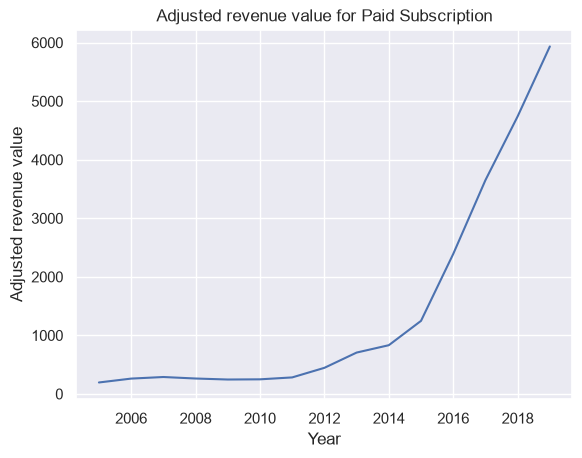

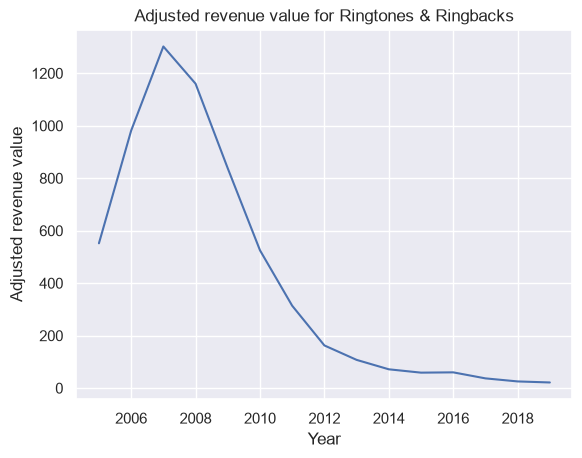

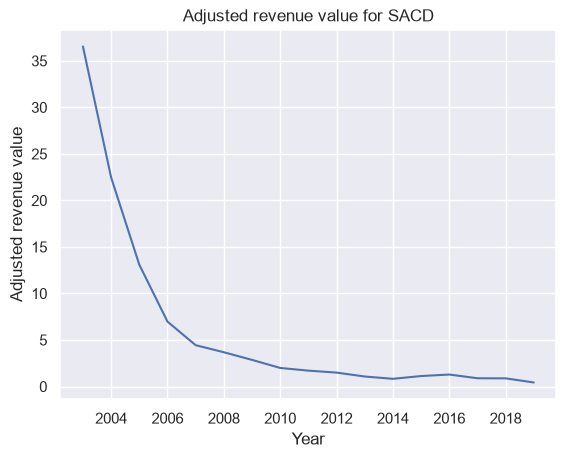

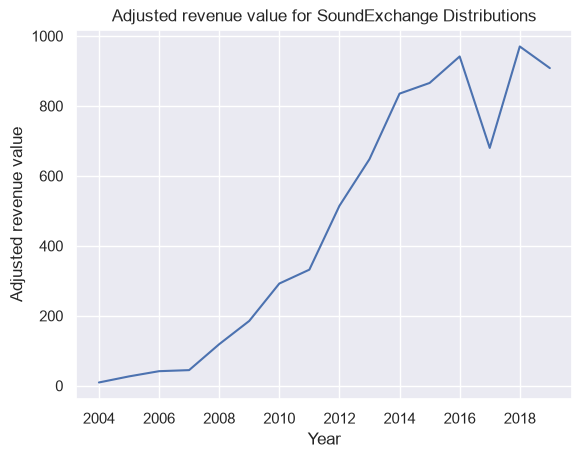

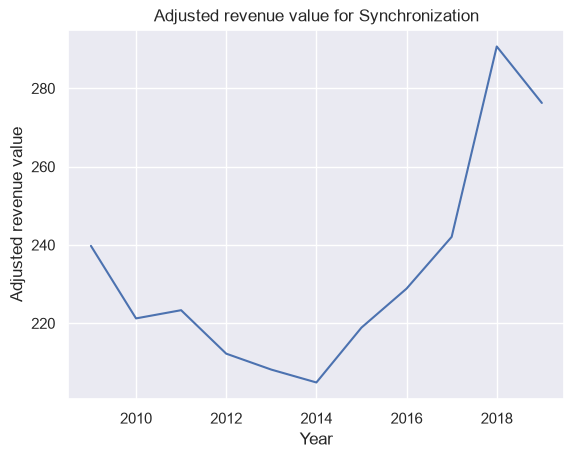

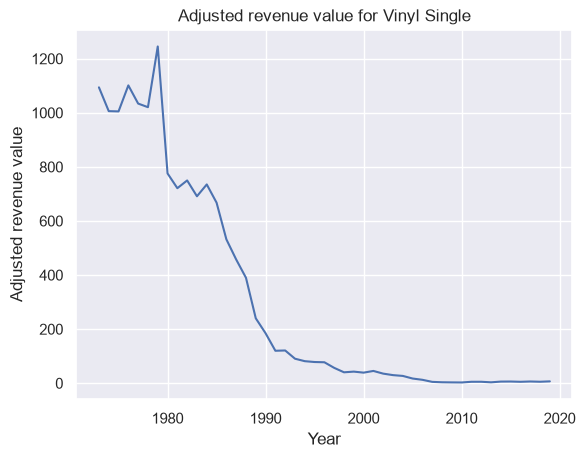

In [79]:
for format in music_adj['format'].unique():
    sns.lineplot(data=music_adj[music_adj['format']==format],x='year',y='value_actual');
    plt.ylabel('Adjusted revenue value');
    plt.xlabel('Year');
    plt.title('Adjusted revenue value for '+format);
    plt.show();

Let's focus on the years 1990 - 2005, where the peak occurred.

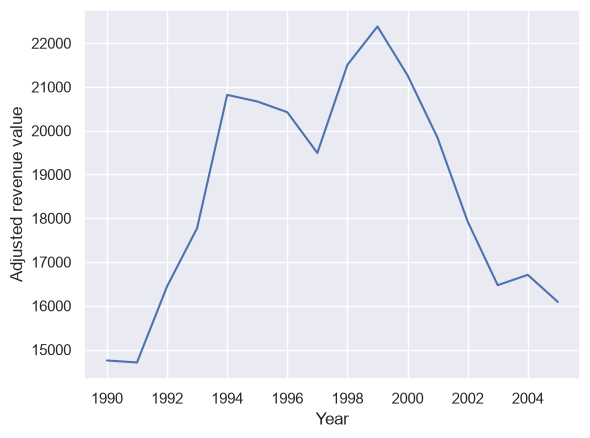

In [80]:
music_peak = music_adj[(music_adj['year']>=1990) & (music_adj['year']<=2005)]
sns.lineplot(data=music_peak.groupby('year',as_index=False)['value_actual'].sum(),
             x='year', y='value_actual');
plt.ylabel('Adjusted revenue value');
plt.xlabel('Year');

Let's determine which formats produced the greatest values in this period.

In [81]:
music_f_peak = music_peak.groupby('format',as_index=False)['value_actual'].sum().sort_values(
    'value_actual',ascending=False)
music_f_peak

,format,value_actual
0,CD,236248.212281
2,Cassette,43634.198070
10,Music Video (Physical),7735.941535
3,Cassette Single,3619.896922
1,CD Single,2372.607796
15,Vinyl Single,1087.015251
9,LP/EP,740.354946
7,Download Single,662.346010
12,Ringtones & Ringbacks,551.894476
5,Download Album,239.217399


Now we do the same with the early and late years.

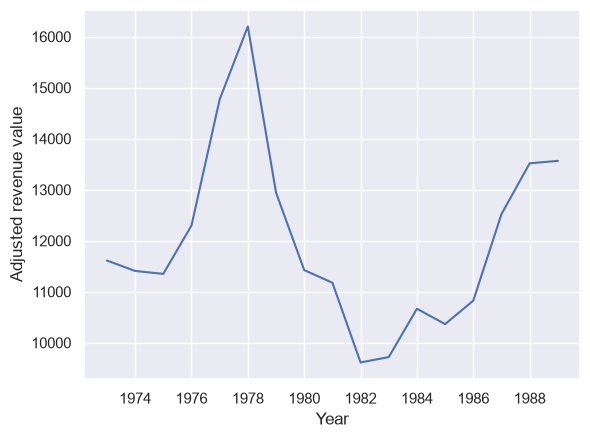

In [88]:
music_early = music_adj[music_adj['year']<1990]
sns.lineplot(data=music_early.groupby('year',as_index=False)['value_actual'].sum(),
             x='year', y='value_actual');
plt.ylabel('Adjusted revenue value');
plt.xlabel('Year');

In [90]:
music_f_early = music_early.groupby('format',as_index=False)['value_actual'].sum().sort_values(
    'value_actual',ascending=False)
music_f_early

,format,value_actual
5,LP/EP,90320.455083
3,Cassette,58668.444111
0,8 - Track,23640.456657
1,CD,16831.418619
8,Vinyl Single,13466.106420
4,Cassette Single,557.229208
6,Music Video (Physical),237.925950
7,Other Tapes,230.180841
2,CD Single,19.735461


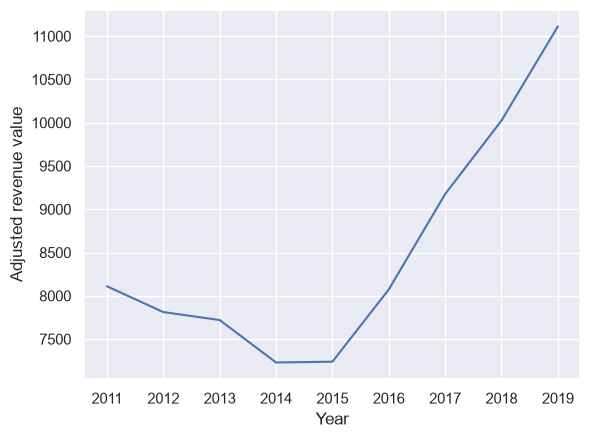

In [82]:
music_late = music_adj[music_adj['year']>2010]
sns.lineplot(data=music_late.groupby('year',as_index=False)['value_actual'].sum(),
             x='year', y='value_actual');
plt.ylabel('Adjusted revenue value');
plt.xlabel('Year');

In [83]:
music_f_late = music_late.groupby('format',as_index=False)['value_actual'].sum().sort_values(
    'value_actual',ascending=False)
music_f_late

,format,value_actual
13,Paid Subscription,20228.685869
0,CD,15751.118906
5,Download Single,10611.097002
3,Download Album,8791.923827
16,SoundExchange Distributions,6695.012887
10,On-Demand Streaming (Ad-Supported),4159.447624
7,LP/EP,2877.110289
8,Limited Tier Paid Subscription,2487.659115
17,Synchronization,2105.361406
11,Other Ad-Supported Streaming,866.632070


It is clear from comparison that, while the recent increase in value is led by paid subscriptions, CDs have seen a huge fall in their value from the 2000s to the 2010s. We can plot the first 3 formats of each period along the entire available years to get a better picture:

In [91]:
top3_00 = music_f_peak['format'].head(3).tolist()
top3_80 = music_f_early['format'].head(3).tolist()
top3_10 = music_f_late['format'].head(3).tolist()
formats = set(top3_00 + top3_80 + top3_10)
formats

{'8 - Track',
 'CD',
 'Cassette',
 'Download Single',
 'LP/EP',
 'Music Video (Physical)',
 'Paid Subscription'}

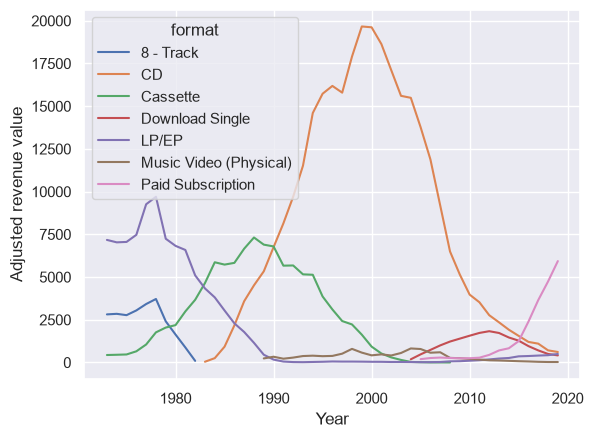

In [92]:
sns.lineplot(data=music_adj[music_adj['format'].isin(formats)],x='year',y='value_actual',hue='format');
plt.xlabel('Year');
plt.ylabel('Adjusted revenue value');